# EX4 Exploratory Data Analysis

## Part 0:
    
The following Git repository is for the COVID-19 visual dashboard operated by the Johns Hopkins University Center for Systems Science and Engineering:

https://github.com/CSSEGISandData/COVID-19

- Read the information on the dashboard and check the datasets details

- Datasets are located in a folder: csse_covid_19_data

We will walk through the code and see how Python Pandas functions are used to process the data.


##### The example below is COVID19 cases in the US.

- We download two files but they seem the same. Let's use the file for confirmed cases.

In [2]:
# Download the data from the Web

import os
import urllib.request

datapath = os.path.join("csse_covid_19_data", "csse_covid_19_data", "")

DOWNLOAD_ROOT = (
    "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/"
    "csse_covid_19_data/csse_covid_19_time_series/"
)

os.makedirs(datapath, exist_ok=True)

for filename in (
    "time_series_covid19_confirmed_US.csv",
    "time_series_covid19_deaths_US.csv"
):
    print("Downloading", filename)

    url = DOWNLOAD_ROOT + filename

    urllib.request.urlretrieve(
        url,
        os.path.join(datapath, filename)
    )

In [3]:
# import necessary packages and modules

import pandas as pd
import matplotlib.pyplot as plt

### Read data

In [4]:
# read data
df = pd.read_csv(datapath + "time_series_covid19_confirmed_US.csv")
df.head()

,UID,iso2,iso3,code3,FIPS,Admin2,Province_State,Country_Region,Lat,Long_,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
0,84001001,US,USA,840,1001.0,Autauga,Alabama,US,32.539527,-86.644082,...,19732,19759,19759,19759,19759,19759,19759,19759,19790,19790
1,84001003,US,USA,840,1003.0,Baldwin,Alabama,US,30.727750,-87.722071,...,69641,69767,69767,69767,69767,69767,69767,69767,69860,69860
2,84001005,US,USA,840,1005.0,Barbour,Alabama,US,31.868263,-85.387129,...,7451,7474,7474,7474,7474,7474,7474,7474,7485,7485
3,84001007,US,USA,840,1007.0,Bibb,Alabama,US,32.996421,-87.125115,...,8067,8087,8087,8087,8087,8087,8087,8087,8091,8091
4,84001009,US,USA,840,1009.0,Blount,Alabama,US,33.982109,-86.567906,...,18616,18673,18673,18673,18673,18673,18673,18673,18704,18704


#### We select data for two states, Washington and Texas

- If you want to select different states, modify this cell and rerun it.

In [5]:
# Select the data for Washington and Texas
st1 = df.loc[df["Province_State"] == "Washington"]
st2 = df.loc[df["Province_State"] == "Texas"]

# drop not-used columns
drop_cols = ['UID', 'iso2', 'iso3', 'FIPS', 'Province_State', 'Country_Region',
             'Lat', 'Long_', 'code3', 'Combined_Key', 'Admin2']

st1 = st1.drop(columns=drop_cols)
st2 = st2.drop(columns=drop_cols)

print(st1.head())
print(st2.head())

st1.columns

      1/22/20  1/23/20  1/24/20  1/25/20  1/26/20  1/27/20  1/28/20  1/29/20  \
3145        0        0        0        0        0        0        0        0   
3146        0        0        0        0        0        0        0        0   
3147        0        0        0        0        0        0        0        0   
3148        0        0        0        0        0        0        0        0   
3149        0        0        0        0        0        0        0        0   

      1/30/20  1/31/20  ...  2/28/23  3/1/23  3/2/23  3/3/23  3/4/23  3/5/23  \
3145        0        0  ...     5631    5647    5647    5647    5647    5647   
3146        0        0  ...     5595    5606    5606    5606    5606    5606   
3147        0        0  ...    61953   62042   62042   62042   62042   62042   
3148        0        0  ...    24120   24171   24171   24171   24171   24171   
3149        0        0  ...    15762   15809   15809   15809   15809   15809   

      3/6/23  3/7/23  3/8/23  3/9/23  

Index(['1/22/20', '1/23/20', '1/24/20', '1/25/20', '1/26/20', '1/27/20',
       '1/28/20', '1/29/20', '1/30/20', '1/31/20',
       ...
       '2/28/23', '3/1/23', '3/2/23', '3/3/23', '3/4/23', '3/5/23', '3/6/23',
       '3/7/23', '3/8/23', '3/9/23'],
      dtype='object', length=1143)

### sum() function

- see the examples:
    
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.sum.html

In [6]:
# sum of column data of rows
# columns and rows will be changed
# sum() function returns a Series
cases_st1 = st1.sum(axis=0)
cases_st2 = st2.sum(axis=0)

print(cases_st1.tail())
print(cases_st2.tail())

3/5/23    1928913
3/6/23    1928913
3/7/23    1928913
3/8/23    1928913
3/9/23    1928913
dtype: int64
3/5/23    8454365
3/6/23    8454724
3/7/23    8455291
3/8/23    8465925
3/9/23    8466220
dtype: int64


In [7]:
# createa a DataFrame of two states' data
dict_states = {'WA_cases': cases_st1, 'TX_cases': cases_st2}

data = pd.DataFrame(dict_states)

print(data.head())
print(data.tail())

         WA_cases  TX_cases
1/22/20         1         0
1/23/20         1         0
1/24/20         1         0
1/25/20         1         0
1/26/20         1         0
        WA_cases  TX_cases
3/5/23   1928913   8454365
3/6/23   1928913   8454724
3/7/23   1928913   8455291
3/8/23   1928913   8465925
3/9/23   1928913   8466220


In [8]:
# reset index (0, 1, 2, . . . ) --> adding number index
data.reset_index(inplace=True)

data.head()

,index,WA_cases,TX_cases
0,1/22/20,1,0
1,1/23/20,1,0
2,1/24/20,1,0
3,1/25/20,1,0
4,1/26/20,1,0


In [9]:
# add two new columns and set default values

data['WA_daily'] = 0
data['TX_daily'] = 0

data.head()

,index,WA_cases,TX_cases,WA_daily,TX_daily
0,1/22/20,1,0,0,0
1,1/23/20,1,0,0,0
2,1/24/20,1,0,0,0
3,1/25/20,1,0,0,0
4,1/26/20,1,0,0,0


In [10]:
# calculate daily cases and assign the values

for index, row in data.iterrows():
    if index==0:
        data.loc[index, 'WA_daily'] = data.loc[index, 'WA_cases']
        data.loc[index, 'TX_daily'] = data.loc[index, 'TX_cases']
    else:
        data.loc[index, 'WA_daily'] = data.loc[index, 'WA_cases'] - data.loc[index-1, 'WA_cases']
        data.loc[index, 'TX_daily'] = data.loc[index, 'TX_cases'] - data.loc[index-1, 'TX_cases']

    # data clearning (drop error values)
    if data.loc[index, 'WA_daily'] < 0:
        data.loc[index, 'WA_daily'] = 0
    if data.loc[index, 'TX_daily'] < 0:
        data.loc[index, 'TX_daily'] = 0

data.tail()

,index,WA_cases,TX_cases,WA_daily,TX_daily
1138,3/5/23,1928913,8454365,0,0
1139,3/6/23,1928913,8454724,0,359
1140,3/7/23,1928913,8455291,0,567
1141,3/8/23,1928913,8465925,0,10634
1142,3/9/23,1928913,8466220,0,295


In [11]:
# add a new column for the number of days
data['day_number'] = data.index

data.head()

,index,WA_cases,TX_cases,WA_daily,TX_daily,day_number
0,1/22/20,1,0,1,0,0
1,1/23/20,1,0,0,0,1
2,1/24/20,1,0,0,0,2
3,1/25/20,1,0,0,0,3
4,1/26/20,1,0,0,0,4


## Part 1

### Tasks

1. (Optional) Select states you are interested in from the COVID-19 data repository. The above cells contain the data for Washington and Texas. Hence if you would like to change states, you will update the above cells and rerun them.

2. Conduct exploratory data analysis on the selected data and visualize the data. This may include the following:

(1) Descriptive statistics: mean, median and standard deviation, mininum, maximum and quatiles.

(2) Draw boxplots.

(3) Draw histograms.

(4) Draw scatter plots and calculate correlation coefficient factor r
    
    - Given an explanatory variable x (e.g., day_number), you display a response variable y (e.g., TX_cases).


(5) Choose one tool that has not be used here and apply it on these COVID-19 data.

#### Task (1)

In [12]:
cols = ['WA_cases', 'TX_cases', 'WA_daily', 'TX_daily']

# describe() gives count, mean, std, min, 25%, 50% (median), 75%, max
stats_table = data[cols].describe()
stats_table.loc['median'] = data[cols].median()   # explicit median row
print(stats_table.round(1))


         WA_cases   TX_cases  WA_daily  TX_daily
count      1143.0     1143.0    1143.0    1143.0
mean     809198.3  3995221.0    1691.2    7407.3
std      710191.1  2966777.6    4467.8   10371.7
min           1.0        0.0       0.0       0.0
25%      113360.0   945866.0       0.0     998.0
50%      507294.0  3374026.0     465.0    4056.0
75%     1573651.0  6910462.0    1765.0    9683.5
max     1928913.0  8466220.0   64166.0   76094.0
median   507294.0  3374026.0     465.0    4056.0


#### Task (2)

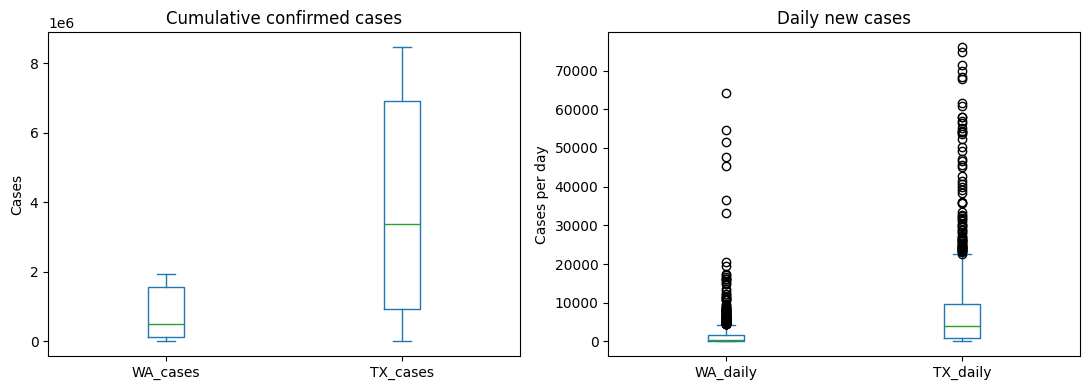

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

data[['WA_cases', 'TX_cases']].plot.box(ax=axes[0])
axes[0].set_title('Cumulative confirmed cases')
axes[0].set_ylabel('Cases')

data[['WA_daily', 'TX_daily']].plot.box(ax=axes[1])
axes[1].set_title('Daily new cases')
axes[1].set_ylabel('Cases per day')

plt.tight_layout()
plt.show()

#### Task (3)

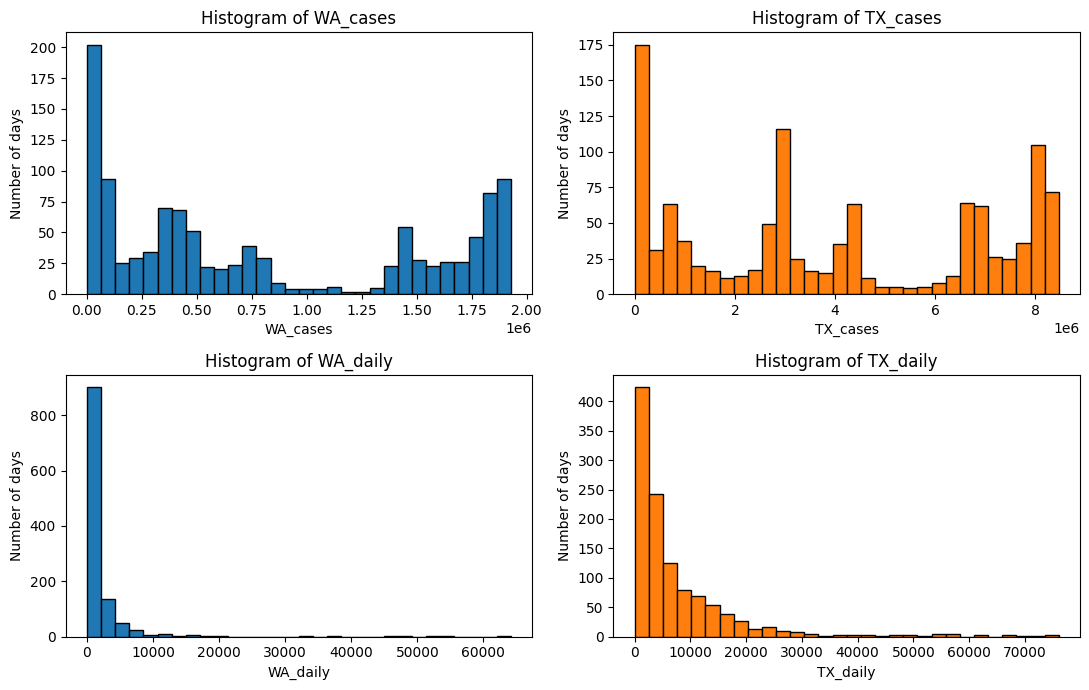

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, c, color in zip(axes.ravel(), cols, ['tab:blue', 'tab:orange', 'tab:blue', 'tab:orange']):
    ax.hist(data[c], bins=30, color=color, edgecolor='black')
    ax.set_title('Histogram of ' + c)
    ax.set_xlabel(c)
    ax.set_ylabel('Number of days')

plt.tight_layout()
plt.show()

#### Task (4)

r(day_number, WA_cases) = 0.9667
r(day_number, TX_cases) = 0.9885
r(day_number, WA_daily) = 0.1065
r(day_number, TX_daily) = 0.0706


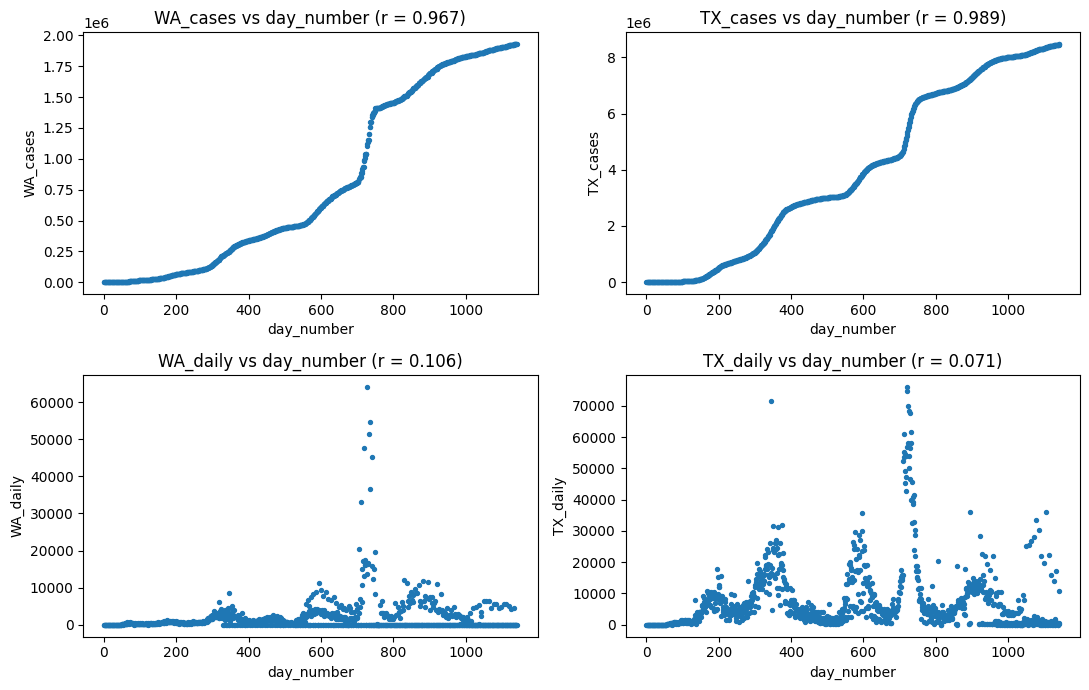


r(WA_cases, TX_cases) = 0.9881
r(WA_daily, TX_daily) = 0.4693


In [15]:
# x = day_number (explanatory), y = cases / daily cases (response)
pairs = ['WA_cases', 'TX_cases', 'WA_daily', 'TX_daily']
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, y in zip(axes.ravel(), pairs):
    r = data['day_number'].corr(data[y])      # Pearson correlation coefficient
    ax.scatter(data['day_number'], data[y], s=8)
    ax.set_title(f'{y} vs day_number (r = {r:.3f})')
    ax.set_xlabel('day_number')
    ax.set_ylabel(y)
    print(f'r(day_number, {y}) = {r:.4f}')

plt.tight_layout()
plt.show()

# Bonus: relationship between the two states
print('\nr(WA_cases, TX_cases) =', round(data['WA_cases'].corr(data['TX_cases']), 4))
print('r(WA_daily, TX_daily) =', round(data['WA_daily'].corr(data['TX_daily']), 4))

#### Task (5)

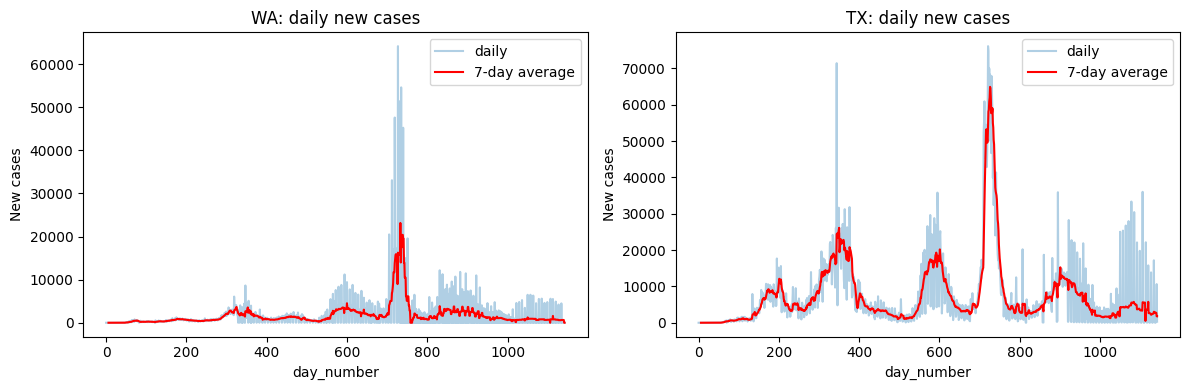

WA: peak 7-day average = 23149 new cases/day on 1/24/22 (day 733)
TX: peak 7-day average = 64897 new cases/day on 1/17/22 (day 726)


In [16]:
# New tool: 7-day rolling (moving) average via DataFrame.rolling()
# Raw daily counts are very noisy (weekday reporting cycles, backlog dumps),
# so a rolling mean makes the real wave pattern visible.
data['WA_7day'] = data['WA_daily'].rolling(window=7).mean()
data['TX_7day'] = data['TX_daily'].rolling(window=7).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, st in zip(axes, ['WA', 'TX']):
    ax.plot(data['day_number'], data[st + '_daily'], alpha=0.35, label='daily')
    ax.plot(data['day_number'], data[st + '_7day'], color='red', label='7-day average')
    ax.set_title(st + ': daily new cases')
    ax.set_xlabel('day_number')
    ax.set_ylabel('New cases')
    ax.legend()
plt.tight_layout()
plt.show()

for st in ['WA', 'TX']:
    peak = data[st + '_7day'].idxmax()
    print(f"{st}: peak 7-day average = {data.loc[peak, st + '_7day']:.0f} new cases/day "
          f"on {data.loc[peak, 'index']} (day {peak})")

## Part 2

Write a summary of your findings from the data analysis.

### Resources

#### Boxplot
https://towardsdatascience.com/understanding-boxplots-5e2df7bcbd51


- matplotlib.pyplot boxplot demo
https://matplotlib.org/3.1.1/gallery/pyplots/boxplot_demo_pyplot.html


#### matplotlib.pyplot
- scatter plot
https://matplotlib.org/3.3.2/api/_as_gen/matplotlib.pyplot.scatter.html


- histogram plot
https://matplotlib.org/3.3.2/api/_as_gen/matplotlib.pyplot.hist.html


#### pandas DataFrame
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.html


- describe()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.describe.html


- corr()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.corr.html


- hist()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.hist.html


- plot.scatter()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.plot.scatter.html


- pivot()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.pivot.html

## Summary of Findings

Descriptive Statistics: Texas had more reported COVID-19 cases than Washington throughout the study period. The average cumulative cases were about 4.0 million in Texas and 810,000 in Washington. In both states, the mean was higher than the median, showing that the data were right-skewed. Daily cases were also highly skewed because a few days had unusually high numbers.

Boxplots: The cumulative case boxplots showed no outliers, as cases generally increased over time. However, daily case boxplots showed many high outliers, likely due to the Omicron wave and reporting delays. Washington also had many days with zero reported new cases.

Histograms: The cumulative case histograms showed a concentration of lower values from the early stages of the pandemic. Daily cases were right-skewed, with many low counts and a few very high values.

Scatter Plots and Correlation: Cumulative cases had a strong positive correlation with time in Washington (0.967) and Texas (0.989). Daily cases had weak correlations with time because case numbers fluctuated in waves. The cumulative cases in both states were highly correlated (0.988), while daily cases had a moderate correlation (0.469).

Seven-Day Rolling Average: The rolling average made the trends easier to see. Texas peaked at about 64,900 daily cases on January 17, 2022, while Washington peaked at around 23,100 on January 24, 2022. Texas peaked about a week earlier, but the rates were more similar after adjusting for population.

Limitations: The data represent reported cases, not all actual infections. Testing changes, reporting delays, and batch reports may have affected the results. Negative daily changes were also set to zero, which may have influenced the analysis.